# Data Summary

Summary of the selected structure for this project and the similarity of the TCR:pMHCs across different folds of the dataset.

In [1]:
import re

import logomaker
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import openchord
import pandas as pd
import plotly.graph_objects as go
from pyxdameraulevenshtein import damerau_levenshtein_distance

## Summary of data selection workflow for TCR:pMHC structures

In [2]:
with open('../data/logs/select_stcrdab_tcr_pmhc_structures.log', 'r') as fh:
    log = fh.read()

In [3]:
info_messages = [line for line in log.split('\n') if 'INFO:' in line]

count_pattern = re.compile(r'Number of structures: (\d+)')
structure_counts = [
    int(re.search(count_pattern, line).group(1)) for line in info_messages if 'Number of structures:' in line
]
structure_count_line_numbers = [
    line_number for line_number, line in enumerate(info_messages) if 'Number of structures:' in line
]
count_contexts = [
    info_messages[line_number - 1].split('INFO: ', 1)[-1] for line_number in structure_count_line_numbers[1:]
]

In [4]:
selection_df = pd.DataFrame(
    {
        'source': ['STCRDab', *count_contexts[:-1]],
        'target': count_contexts,
        'count': structure_counts[1:],
    }
)

reject_df = selection_df.copy()
reject_df['target'] = 'Reject'
reject_df['count'] = (
    np.concatenate([np.array([structure_counts[0]]), selection_df['count'].to_numpy()[:-1]]) - selection_df['count']
)

selection_df = pd.concat([selection_df, reject_df])

selection_df

,source,target,count
0,STCRDab,"Selecting structures (TCRs: abTCR, MHCs: MH1, ...",429
1,"Selecting structures (TCRs: abTCR, MHCs: MH1, ...",Screening structures above 3.50 Å resolution,419
2,Screening structures above 3.50 Å resolution,Removing structures missing residues,356
3,Removing structures missing residues,Removing structures within 2.00 Å RMSD,251
0,STCRDab,Reject,529
1,"Selecting structures (TCRs: abTCR, MHCs: MH1, ...",Reject,10
2,Screening structures above 3.50 Å resolution,Reject,63
3,Removing structures missing residues,Reject,105


In [5]:
plot_df = selection_df.copy()

unique_source_target = list(np.unique(plot_df[['source', 'target']].to_numpy().flatten()))

mapping_dict = {k: v for v, k in enumerate(unique_source_target)}

plot_df['source'] = plot_df['source'].map(mapping_dict)
plot_df['target'] = plot_df['target'].map(mapping_dict)

fig = go.Figure(
    data=[
        go.Sankey(
            node={
                'pad': 15,
                'thickness': 20,
                'line': {'color': 'black', 'width': 0.5},
                'label': unique_source_target,
            },
            link={
                'source': plot_df['source'],
                'target': plot_df['target'],
                'value': plot_df['count'],
            },
        )
    ]
)

fig.update_layout(title_text='Selected Structures Sankey Diagram', font_size=10, width=1000, height=600)

fig.show()

## Summary of dataset

In [6]:
summary_df = pd.read_csv('../data/interim/structures_summary.csv')

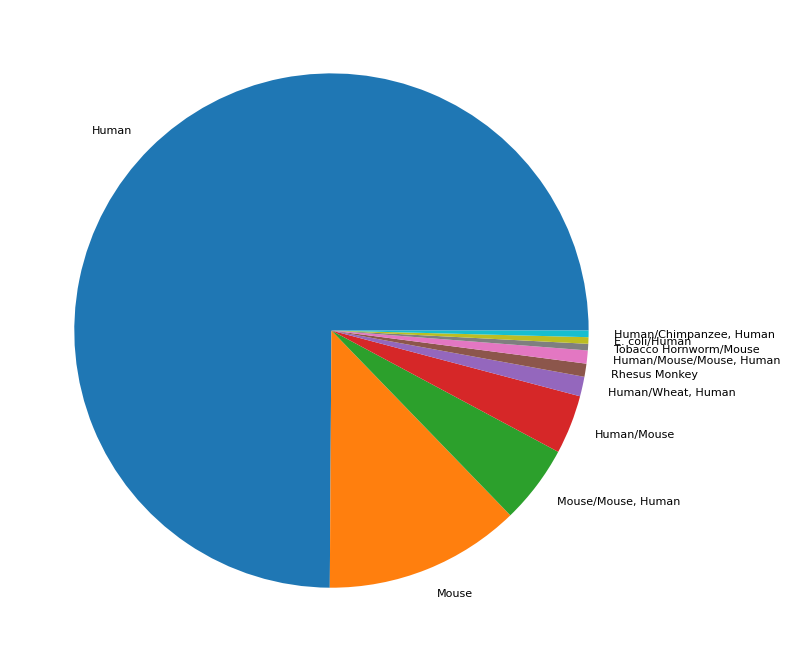

In [ ]:
plt.figure(figsize=(8, 8))

summary_df['species'].value_counts().plot.pie(textprops={'fontsize': 8})

plt.ylabel('')
plt.tight_layout()

plt.show()

###  TCR V-gene pairings

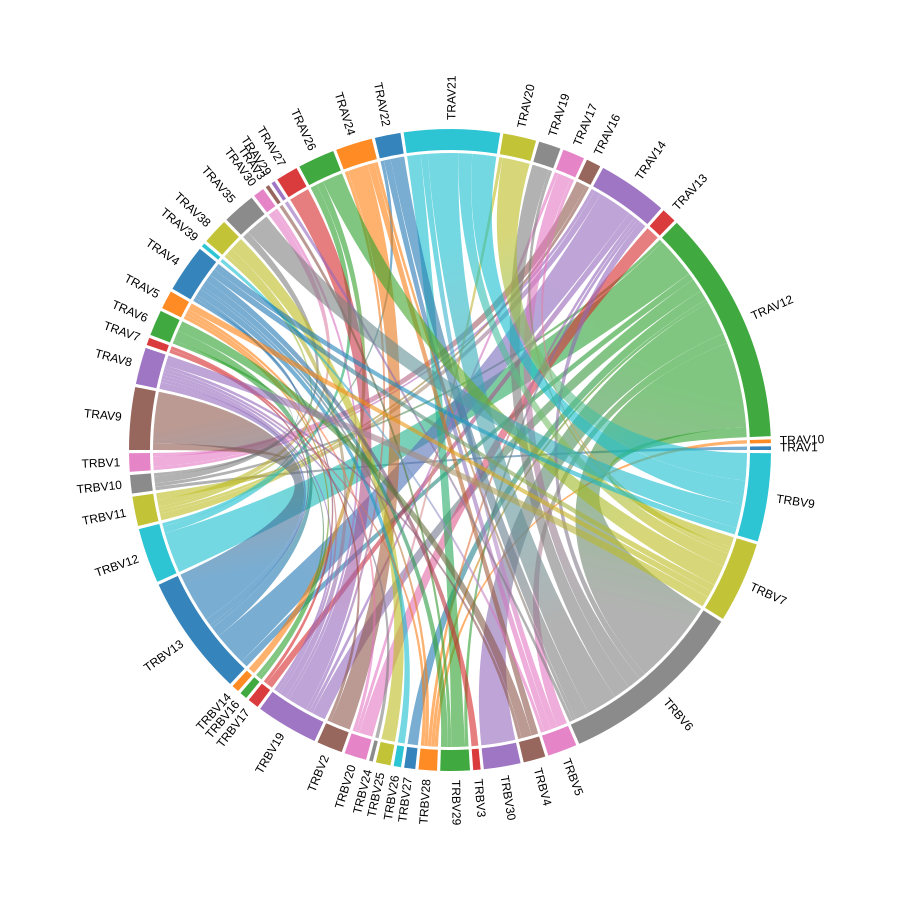

In [ ]:
counts = summary_df.value_counts(['v_alpha', 'v_beta'])
labels = sorted(
    np.concatenate(
        [
            summary_df['v_alpha'].dropna().unique(),
            summary_df['v_beta'].dropna().unique(),
        ]
    ).tolist()
)

num_labels = len(labels)
adjacency_matrix = np.zeros((num_labels, num_labels), dtype=int)

for i in range(num_labels):
    for j in range(i + 1, num_labels):
        try:
            adjacency_matrix[i, j] = counts[labels[i]][labels[j]]
        except KeyError:
            adjacency_matrix[i, j] = 0

adjacency_matrix = np.maximum(adjacency_matrix, adjacency_matrix.transpose())
fig = openchord.Chord(adjacency_matrix, labels)

fig.colormap = list(plt.rcParams['axes.prop_cycle'].by_key()['color'])

fig.radius = 300
fig.padding = 150
fig.font_size = 12

fig.show()

### Similarity of peptides

In [9]:
df_annotated_no_dup_peptides = summary_df.drop_duplicates(['peptide'])
peptide_sequences = df_annotated_no_dup_peptides['peptide'].to_numpy()

In [10]:
distance_matrix = np.zeros((peptide_sequences.shape[0], peptide_sequences.shape[0]), dtype=int)

for i in range(peptide_sequences.shape[0]):
    for j in range(i + 1, peptide_sequences.shape[0]):
        distance_matrix[i, j] = damerau_levenshtein_distance(peptide_sequences[i], peptide_sequences[j])

distance_matrix = np.maximum(distance_matrix, distance_matrix.T)

print(
    f'The average levenshtein distance between all peptide sequences is {np.average(distance_matrix):.2f} edits',
    f'with an standard deviation of {np.std(distance_matrix):.2f} edits.',
)

The average levenshtein distance between all peptide sequences is 9.19 edits with an standard deviation of 2.10 edits.


In [11]:
CUTOFF_PERCENT = 70

sequence_lengths = np.array([len(seq) for seq in peptide_sequences])
grid1, grid2 = np.meshgrid(sequence_lengths, sequence_lengths)

max_lengths = np.maximum(grid1, grid2)
sequence_percent_identities = ((max_lengths - distance_matrix) / max_lengths) * 100

similar_peptides = sequence_percent_identities > CUTOFF_PERCENT

In [12]:
G = nx.Graph()
G.add_nodes_from(range(peptide_sequences.shape[0]))

for i in range(1, peptide_sequences.shape[0]):
    for j in range(i + 1, peptide_sequences.shape[0]):
        if similar_peptides[i, j]:
            G.add_edge(i, j, weight=sequence_percent_identities[i, j] / 100)

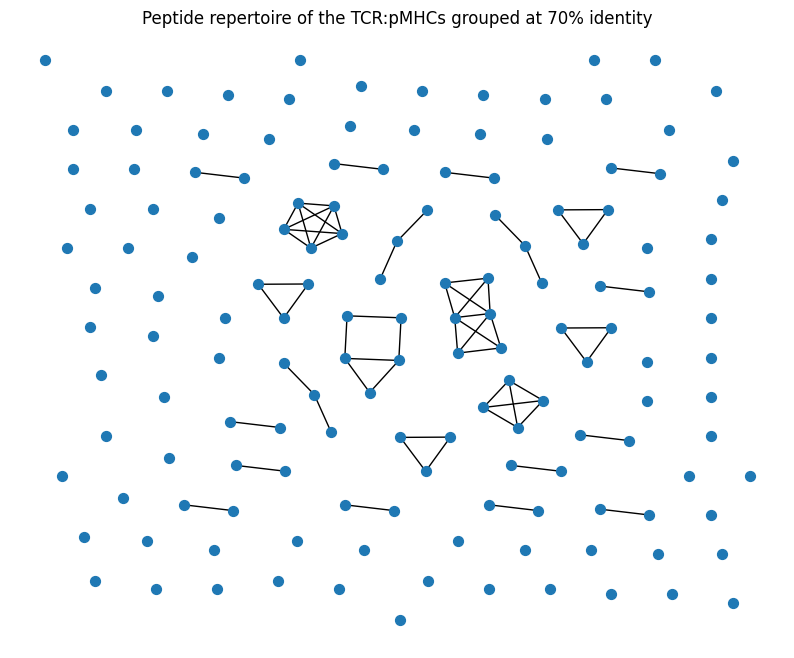

In [ ]:
plt.figure(figsize=(10, 8))
plt.title(f'Peptide repertoire of the TCR:pMHCs grouped at {CUTOFF_PERCENT}% identity')

nx.draw(
    G,
    node_size=50,
    pos=nx.drawing.nx_agraph.graphviz_layout(G, prog='neato'),
)

plt.show()

### Proportion of MHC types

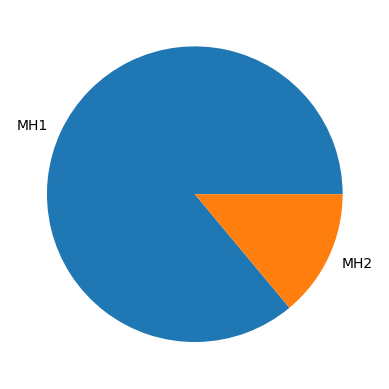

In [ ]:
summary_df['mhc_type'].value_counts().plot.pie()

plt.ylabel('')

plt.show()

In [15]:
summary_df[['mhc1', 'mhc2']] = summary_df[['mhc1', 'mhc2']].fillna('Unknown')

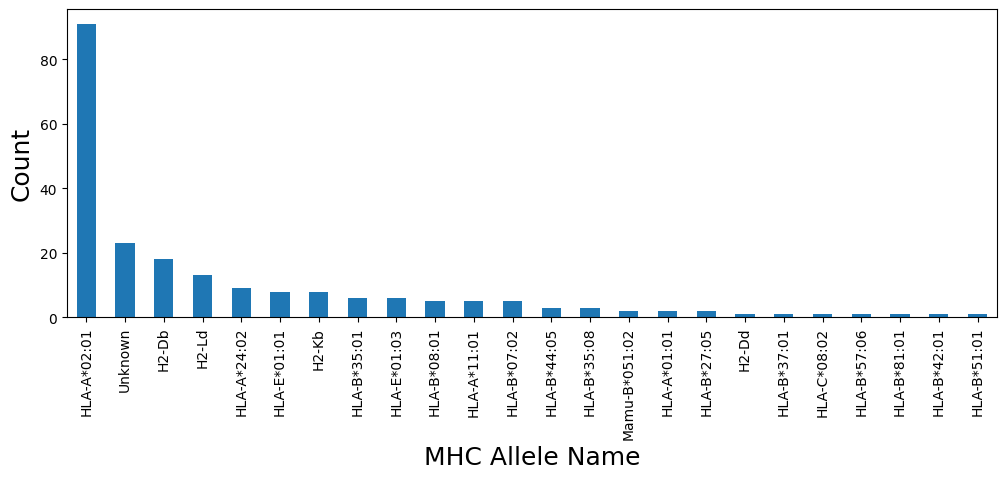

In [ ]:
summary_df.query("mhc_type == 'MH1'")['mhc1'].value_counts().plot.bar(figsize=(12, 4))

plt.ylabel('Count', fontsize=18)
plt.xlabel('MHC Allele Name', fontsize=18)

plt.show()

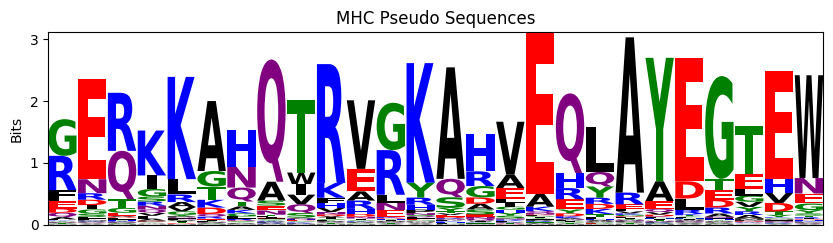

In [ ]:
probs = logomaker.alignment_to_matrix(summary_df['mhc_pseudo'], to_type='information')
logomaker.Logo(probs, color_scheme='chemistry')

plt.title('MHC Pseudo Sequences')
plt.ylabel('Bits')
plt.xticks([])

plt.show()